# Exploratory Data Analysis (EDA)

This notebook explores the cleaned Chicago 2025 crash dataset (`cleaned_crashes.csv`). The objectives are:
- To analyze how external driving conditions (lighting, weather, road surface, time of day, and speed limit) affect the risk of personal injury **(injury)** in traffic accidents.
- To establish the empirical foundation and define the guidelines for preprocessing, feature engineering, and model selection for the next stages of the pipeline.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Load the cleaned dataset
df = pd.read_csv("../data/cleaned_crashes.csv")

# Styling 
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Calibri, Arial, sans-serif'
plt.rcParams['axes.edgecolor'] = '#E4E4E9'
plt.rcParams['axes.linewidth'] = 1.2

CRIMSON = "#D43A63"
SLATE = "#33363E"
LIGHT_GREY = "#E4E4E9"

# Selected predictors and target variable
predictors = [
    'POSTED_SPEED_LIMIT',
    'WEATHER_CONDITION',
    'LIGHTING_CONDITION',
    'ROADWAY_SURFACE_COND',
    'CRASH_HOUR'
]
target = 'injury'

## 1. Mapping of variable scales
Before we analyze the relationships, the measurement scales of the variables must be determined.

In [ ]:
eda_df = df[[target] + predictors].copy()
print(f"The dataset contains {eda_df.shape[0]:,} accidents and {eda_df.shape[1]} selected variables.")
eda_df.info()

The dataset contains 108,903 accidents and 6 selected variables.
<class 'pandas.DataFrame'>
RangeIndex: 108903 entries, 0 to 108902
Data columns (total 6 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   injury                108903 non-null  int64  
 1   POSTED_SPEED_LIMIT    108705 non-null  float64
 2   WEATHER_CONDITION     108903 non-null  str    
 3   LIGHTING_CONDITION    108903 non-null  str    
 4   ROADWAY_SURFACE_COND  108903 non-null  str    
 5   CRASH_HOUR            108903 non-null  float64
dtypes: float64(2), int64(1), str(3)
memory usage: 5.0 MB


We see that the variables `WEATHER_CONDITION`, `LIGHTING_CONDITION`, and `ROADWAY_SURFACE_COND` are categories representing pure labels with no inherent mathematical ranking. They cannot be treated as numbers, and we can only use mode and frequency counts as valid summaries. 

`CRASH_HOUR` represents clock hours ranging from 0 to 23. Although the values are numerical, their origin (midnight) is based on convention; it is therefore an interval scale and discrete in practice, where median, mode, and differences (elapsed time) are valid summaries. We must also examine whether the risk develops linearly or cyclically before including the variable in models. 

`POSTED_SPEED_LIMIT` has a true zero point and allows for arithmetic comparisons (e.g. 60 mph is twice 30 mph). It is therefore on a ratio scale and discrete (recorded in whole mph), where mean, median, and mode are valid summaries. 

**Summed up, we get the following classification table:**

| Column | Scale | Discrete or Continuous | Valid Summary |
| --- | --- | --- | --- |
| `WEATHER_CONDITION` | Nominal | Discrete | Mode, frequency counts |
| `LIGHTING_CONDITION` | Nominal | Discrete | Mode, frequency counts |
| `ROADWAY_SURFACE_COND` | Nominal | Discrete | Mode, frequency counts |
| `POSTED_SPEED_LIMIT` | Ratio | Discrete | Mean, median, mode, IQR |
| `CRASH_HOUR` | Interval | Discrete | Median, mode, differences |

## 2. Base rate and class Imbalance

In [ ]:
target_counts = eda_df["injury"].value_counts()
target_percents = eda_df["injury"].value_counts(normalize=True) * 100

target_summary = pd.DataFrame(
    {"Number of accidents": target_counts, "Share (%)": target_percents.round(2)}
)
target_summary.index = ["Property damage only (0)", "At least one personal injury (1)"]
print(target_summary)

                                  Number of accidents  Share (%)
Property damage only (0)                        91001      83.56
At least one personal injury (1)                17902      16.44


### Findings
The base rate for personal injury in the population is **16.44%** ($P(\text{injury}) \approx 0.164$). This represents an imbalance of approximately 1:5.

Because a naive baseline model that always predicts no injury (0) would achieve an accuracy of 83.56% while completely failing to identify injury cases (0% recall), the modeling phase must employ cost adjustment or balanced class weights `(class_weight='balanced')` to compel the algorithms to detect positive cases. Consequently, the downstream evaluation phase must prioritize metrics like Recall, Precision, and PR-AUC/F1-score over simple Accuracy, as overall accuracy would provide a misleading impression of performance on this imbalanced dataset.

## 3. Analysis of the explanatory variables

### 3.1 LIGHTING_CONDITION
We begin by analyzing how lighting conditions correlate with crash severity. Because `LIGHTING_CONDITION` is a **nominal variable**, we examine frequency counts and the conditional probability of injury: 
    
- $P(\text{injury} \mid \text{lighting})$.

                        Total crashes  Injuries  Injury rate (%)
LIGHTING_CONDITION                                              
All                            108903     17902              NaN
DAYLIGHT                        70461     11218            15.92
DARKNESS, LIGHTED ROAD          22567      4679            20.73
UNKNOWN                          6829       378             5.54
DARKNESS                         4533       744            16.41
DUSK                             2811       541            19.25
DAWN                             1702       342            20.09


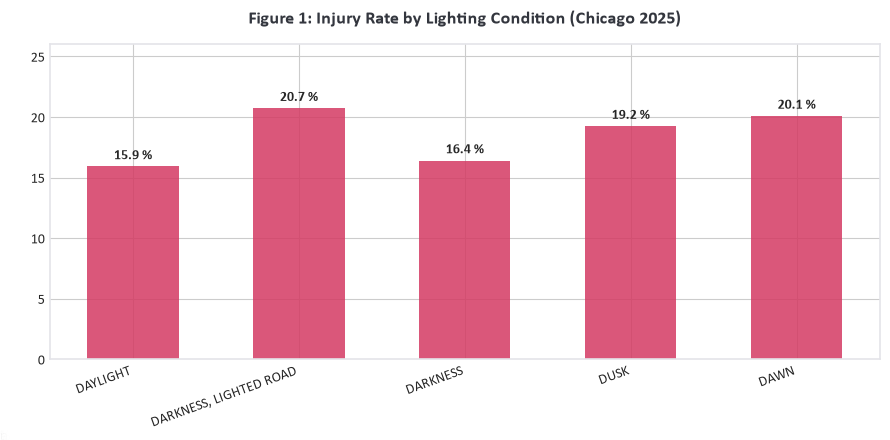

In [ ]:
# Contingency table for lighting conditions
light_tab = pd.crosstab(eda_df['LIGHTING_CONDITION'], eda_df['injury'], margins=True)
light_percent = pd.crosstab(eda_df['LIGHTING_CONDITION'], eda_df['injury'], normalize='index') * 100

light_summary = pd.DataFrame({
    'Total crashes': light_tab['All'],
    'Injuries': light_tab[1],
    'Injury rate (%)': light_percent[1].round(2)
}).sort_values(by='Total crashes', ascending=False)

print(light_summary)

# Figure 1: Injury rate by lighting conditions (excludes 'All' and 'UNKNOWN')
plot_light = light_summary.drop(['All', 'UNKNOWN'], errors='ignore')

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(plot_light.index, plot_light['Injury rate (%)'], color=CRIMSON, alpha=0.85, width=0.55)

ax.set_ylabel("Injury rate (%)", fontsize=11, color=SLATE)
ax.set_title("Figure 1: Injury Rate by Lighting Condition (Chicago 2025)", fontsize=13, fontweight='bold', pad=15, color=SLATE)
ax.set_ylim(0, 26)
plt.xticks(rotation=20, ha='right', fontsize=10)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.6, f"{yval:.1f} %", ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

**Findings**  
While the absolute volume of crashes occurs in daylight with 70,461 crashes and 15.9% injury rate, the risk of injury increases significantly under dark conditions like lighted roads with 22,567 crashes and **20.7%** injury rate, dusk with 2,811 crashes and **19,2%** injury rate, and dawn with 1,702 crashes and **20,1%** injury rate. Reduced natural visibility is a strong indicator of accident severity.

### 3.2 WEATHER_CONDITION & ROADWAY_SURFACE_COND

Like lighting conditions, `WEATHER_CONDITION` and `ROADWAY_SURFACE_COND` are **nominal variables**. However, these two features differ fundamentally from lighting in two key ways:
1. They have a high mutual dependence, meaning rain causes wet roads, and snow produces slush/ice.
2. Drivers usually visibly adapt to severe winter hazards like snow/ice by reducing driving speed. Wet or rain conditions may not trigger the same caution.

Below, we examine the independent distributions and their joint interaction via cross-tabulation and a heatmap.

In [ ]:
# 1. Summary of weather conditions
weather_tab = pd.crosstab(eda_df['WEATHER_CONDITION'], eda_df['injury'], margins=True)
weather_percent = pd.crosstab(eda_df['WEATHER_CONDITION'], eda_df['injury'], normalize='index') * 100

weather_summary = pd.DataFrame({
    'Total crashes': weather_tab['All'],
    'Injuries': weather_tab[1],
    'Injury rate (%)': weather_percent[1].round(2)
}).sort_values(by='Total crashes', ascending=False)

print("=== Weather Conditions vs. Injury ===")
print(weather_summary)

# 2. Summary of road surfacing
road_tab = pd.crosstab(eda_df['ROADWAY_SURFACE_COND'], eda_df['injury'], margins=True)
road_percent = pd.crosstab(eda_df['ROADWAY_SURFACE_COND'], eda_df['injury'], normalize='index') * 100

road_summary = pd.DataFrame({
    'Total crashes': road_tab['All'],
    'Injuries': road_tab[1],
    'Injury rate (%)': road_percent[1].round(2)
}).sort_values(by='Total crashes', ascending=False)

print("\n=== Road Surface Conditions vs. Injury ===")
print(road_summary)

=== Weather Conditions vs. Injury ===
                          Total crashes  Injuries  Injury rate (%)
WEATHER_CONDITION                                                 
All                              108903     17902              NaN
CLEAR                             85569     14767            17.26
UNKNOWN                            8821       554             6.28
RAIN                               6555      1359            20.73
SNOW                               3548       480            13.53
CLOUDY/OVERCAST                    3061       529            17.28
FREEZING RAIN/DRIZZLE               592        75            12.67
OTHER                               468        82            17.52
SLEET/HAIL                          129        24            18.60
BLOWING SNOW                         75        22            29.33
FOG/SMOKE/HAZE                       63         7            11.11
BLOWING SAND, SOIL, DIRT             13         2            15.38
SEVERE CROSS WIND GATE  


To ensure statistical reliability and interpretability, the heatmap focuses on the four most frequent categories for both weather (`CLEAR`, `RAIN`, `SNOW`, `CLOUDY/OVERCAST`) and roadway surface (`DRY`, `WET`, `SNOW OR SLUSH`, `ICE`). 
 
The reasons for choosing only these categories are:
1. These primary combinations represent **91,427 crashes (83.95% of the total dataset)**, capturing the vast majority of real-world driving conditions in Chicago.
2. The excluded categories (such as `SEVERE CROSS WIND GATE`, `BLOWING SAND`, or `SAND, MUD, DIRT`) account for less than 1.3% of crashes combined. Many of their cross-combinations contain only 1 to 3 observations, which artificially inflates cell rates to extreme values (e.g., 50% or 100%) due to small sample sizes rather than true systematic risk.
3. Missing/unknown labels (8.1% in weather, 14.1% in surface condition) provide no physical insight into road grip or visibility and `UNKNOWN` is therfore omitted to avoid cluttering the comparative risk matrix.

ROADWAY_SURFACE_COND        DRY        ICE  SNOW OR SLUSH        WET
WEATHER_CONDITION                                                   
CLEAR                 17.872720  13.480392      16.024096  19.248826
CLOUDY/OVERCAST       18.181818   3.571429      14.117647  20.087336
RAIN                  10.980392   2.380952      19.230769  21.582852
SNOW                  15.662651  14.124294      12.943116  16.036506


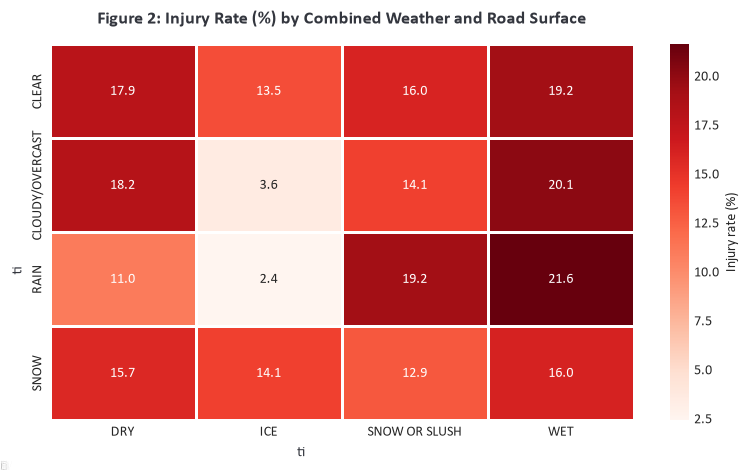

In [ ]:
# Select the most frequent categories to avoid noise from micro-categories
top_weather = ['CLEAR', 'RAIN', 'SNOW', 'CLOUDY/OVERCAST']
top_road = ['DRY', 'WET', 'SNOW OR SLUSH', 'ICE']

subset = eda_df[eda_df['WEATHER_CONDITION'].isin(top_weather) & 
                eda_df['ROADWAY_SURFACE_COND'].isin(top_road)]

# Cross-tabulate mean injury rate (%)
heatmap_data = pd.crosstab(
    subset['WEATHER_CONDITION'],
    subset['ROADWAY_SURFACE_COND'],
    values=subset['injury'],
    aggfunc='mean'
) * 100

print(heatmap_data)

# Plot heatmap
plt.figure(figsize=(8, 4.8))
sns.heatmap(heatmap_data, annot=True, fmt=".1f", cmap="Reds", 
            cbar_kws={'label': 'Injury rate (%)'}, linewidths=1)

plt.title("Figure 2: Injury Rate (%) by Combined Weather and Road Surface", 
          fontsize=13, fontweight='bold', pad=15, color=SLATE)
plt.xlabel("Road surface condition (ROADWAY_SURFACE_COND)", fontsize=11, color=SLATE)
plt.ylabel("Weather condition (WEATHER_CONDITION)", fontsize=11, color=SLATE)
plt.tight_layout()
plt.show()

**Findings**  
* **The Wet/Rain Peak:** Rain combined with wet asphalt exhibits the highest injury rate among common driving conditions (~20.5%–20.7%). This indicates that reduced surface friction without a corresponding reduction in vehicle speed increases impact severity.
* **The Winter Hazard Paradox:** Extreme winter conditions such as Snow (13.5%) and Ice (10.3%) show substantially lower proportions of personal injury. This can mean that drivers compensate by driving at reduced speeds, turning potential injury crashes into low-speed property-damage incidents.

### 3.3 CRASH_HOUR
`CRASH_HOUR` is recorded as an integer from 0 to 23. Below, we compare total accident volume against the conditional injury rate for each hour to assess whether time of day has a linear or cyclical relationship with risk.

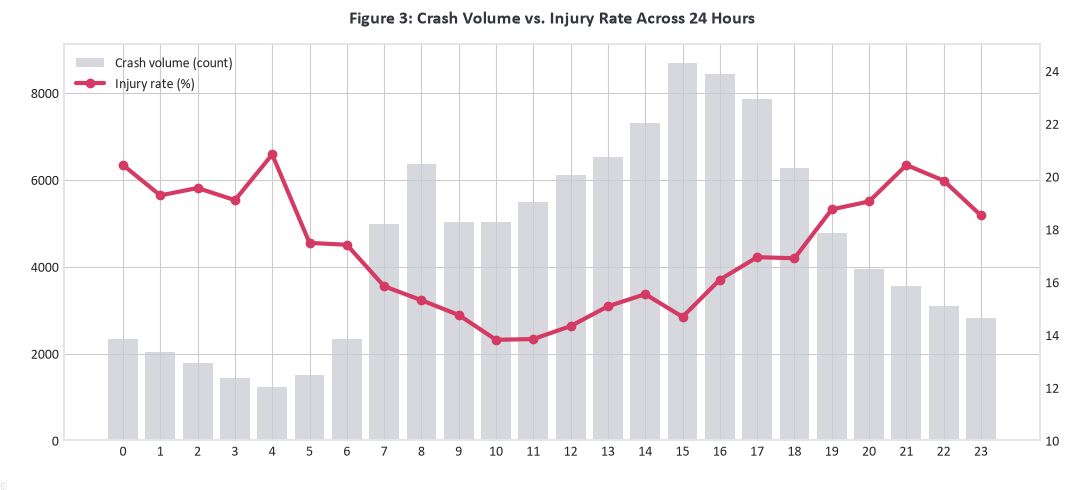

In [ ]:
hour_tab = pd.crosstab(eda_df['CRASH_HOUR'], eda_df['injury'])
hour_rate = pd.crosstab(eda_df['CRASH_HOUR'], eda_df['injury'], normalize='index')[1] * 100

hour_df = pd.DataFrame({
    'Crashes': hour_tab.sum(axis=1),
    'Injury rate (%)': hour_rate.round(2)
})

# Figure 2: Daily variation with dual axes
fig, ax1 = plt.subplots(figsize=(11, 5))

# Columns for volume
ax1.bar(hour_df.index, hour_df['Crashes'], color='#C9CCD4', alpha=0.75, label='Crash volume (count)')
ax1.set_xlabel("Hour of day (0–23)", fontsize=11, color=SLATE)
ax1.set_ylabel("Total crashes", fontsize=11, color=SLATE)
ax1.set_xticks(range(24))

# Injury rate line
ax2 = ax1.twinx()
ax2.plot(hour_df.index, hour_df['Injury rate (%)'], color=CRIMSON, linewidth=3, marker='o', label='Injury rate (%)')
ax2.set_ylabel("Injury rate (%)", fontsize=11, color=CRIMSON)
ax2.set_ylim(10, 25)
ax2.grid(False)

plt.title("Figure 3: Crash Volume vs. Injury Rate Across 24 Hours", fontsize=13, fontweight='bold', pad=15, color=SLATE)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.tight_layout()
plt.show()

**Findings**  
Figure 3 uncovers a major non-linear divergence between crash frequency and crash severity:
* **Crash volume** peaks during the afternoon rush hour (15:00–17:00), exceeding 8,000 crashes per hour.
* **Injury rate** reaches its lowest point during midday (~13.8%), but surges during night-time and early morning hours (21:00–04:00), consistently exceeding **19–20%**.
 
Because risk follows a cyclical pattern rather than a monotonic slope, treating `CRASH_HOUR` as a continuous ratio/interval variable would severely bias a linear classifier like Logistic Regression.

### 3.4 POSTED_SPEED_LIMIT

`POSTED_SPEED_LIMIT` is a numerical predictor measured on a **ratio scale** with a true natural zero. During data cleaning, 198 recorded zero-values were converted to missing values (`NaN`) because zero was deemed invalid for a posted speed limit in traffic reporting. In this section, we examine the distribution and spread of speed limits by contrasting the **mean** against the **median** and **IQR** in the presence of heavy tails and outliers. This establishes the empirical basis for imputing the missing values via the training set median, while evaluating how speed limit zones correlate with injury risk to guide feature scaling in the modeling pipeline.

In [ ]:
# 1. Descriptive statistics overall
speed_overall = eda_df['POSTED_SPEED_LIMIT'].describe()
print("=== Overall Posted Speed Limit Statistics ===")
print(speed_overall.round(2))

# 2. Descriptive statistics by injury status
speed_by_injury = eda_df.groupby('injury')['POSTED_SPEED_LIMIT'].describe()
print("\n=== Speed Limit Statistics by Injury Status ===")
print(speed_by_injury[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']].round(2))

# 3. Check frequency of the dominant 30 mph category and extreme values
percent_30 = (eda_df['POSTED_SPEED_LIMIT'] == 30).mean() * 100
low_outliers = (eda_df['POSTED_SPEED_LIMIT'] <= 5).sum()
high_outliers = (eda_df['POSTED_SPEED_LIMIT'] >= 55).sum()

print(f"\nShare of accidents at exactly 30 mph: {percent_30:.2f}%")
print(f"Low outliers (<= 5 mph): {low_outliers:,} crashes")
print(f"High outliers (>= 55 mph): {high_outliers:,} crashes")
print(f"Missing values (NaN) to impute: {eda_df['POSTED_SPEED_LIMIT'].isna().sum()}")

=== Overall Posted Speed Limit Statistics ===
count    108705.00
mean         28.48
std           5.43
min           1.00
25%          30.00
50%          30.00
75%          30.00
max          70.00
Name: POSTED_SPEED_LIMIT, dtype: float64

=== Speed Limit Statistics by Injury Status ===
          count   mean   std  min   25%   50%   75%   max
injury                                                   
0       90828.0  28.28  5.60  1.0  30.0  30.0  30.0  70.0
1       17877.0  29.47  4.37  3.0  30.0  30.0  30.0  65.0

Share of accidents at exactly 30 mph: 74.37%
Low outliers (<= 5 mph): 368 crashes
High outliers (>= 55 mph): 123 crashes
Missing values (NaN) to impute: 198


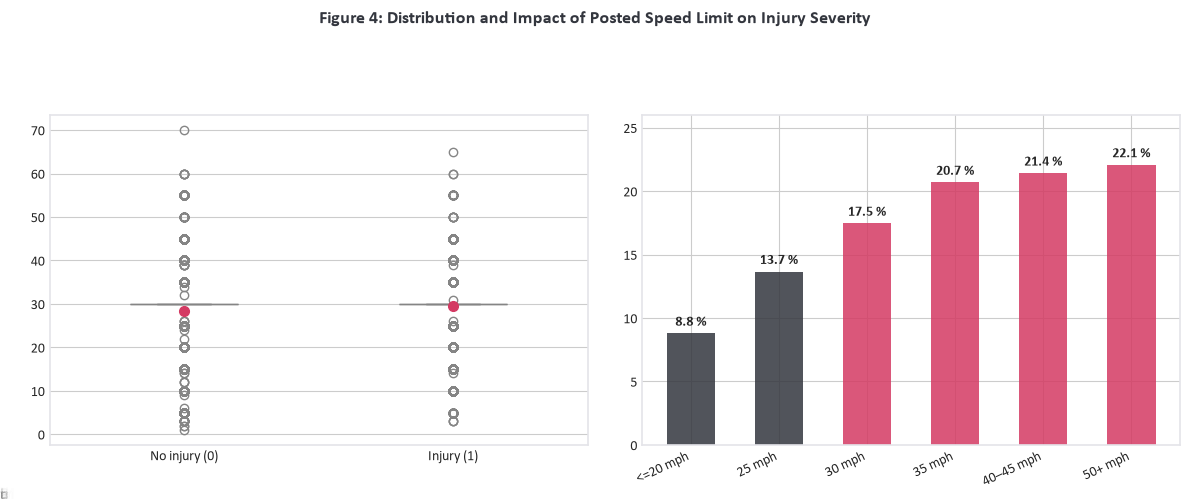

In [ ]:
# Group speed limits into recognizable urban zones
bins = [-1, 20, 25, 30, 35, 45, 100]
labels = ['<=20 mph', '25 mph', '30 mph', '35 mph', '40–45 mph', '50+ mph']

speed_zone_series = pd.cut(eda_df['POSTED_SPEED_LIMIT'], bins=bins, labels=labels)
zone_rates = pd.crosstab(speed_zone_series, eda_df['injury'], normalize='index')[1] * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

# 3a: Box plot by injury status
sns.boxplot(
    data=eda_df, 
    x='injury', 
    y='POSTED_SPEED_LIMIT', 
    hue='injury',
    palette=['#EDEDF1', '#F7C3D2'], 
    legend=False,
    ax=ax1, 
    width=0.4,
    showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": CRIMSON, "markeredgecolor": CRIMSON, "markersize": "7"}
)
# Lock ticks before labels are applied
ax1.set_xticks([0, 1])
ax1.set_xticklabels(['No injury (0)', 'Injury (1)'], fontsize=10)
ax1.set_xlabel("Crash outcome", fontsize=11, color=SLATE)
ax1.set_ylabel("Posted speed limit (mph)", fontsize=11, color=SLATE)
ax1.set_title("Box Plot: Speed Limit by Injury Status\n(Dot = Mean, Line = Median)", fontsize=12, fontweight='bold', color=SLATE)

# 3b: Injury rate by speed zone
bars = ax2.bar(
    zone_rates.index, 
    zone_rates.values, 
    color=[SLATE, SLATE, CRIMSON, CRIMSON, CRIMSON, CRIMSON], 
    alpha=0.85, 
    width=0.55
)
ax2.set_ylabel("Injury rate (%)", fontsize=11, color=SLATE)
ax2.set_title("Injury Rate by Speed Limit Zone", fontsize=12, fontweight='bold', color=SLATE)
ax2.set_ylim(0, 26)
plt.setp(ax2.get_xticklabels(), rotation=25, ha='right', fontsize=10)

for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 0.6, f"{yval:.1f} %", ha='center', fontsize=10, fontweight='bold')

plt.suptitle("Figure 4: Distribution and Impact of Posted Speed Limit on Injury Severity", fontsize=13, fontweight='bold', y=1.03, color=SLATE)
plt.tight_layout()
plt.show()

**Findings**  
* **Distribution and Central Tendency**  
    The distribution of speed limits is heavily concentrated around Chicago's standard default urban speed limit of 30 mph, which accounts for 74.4% of all recorded crashes. Consequently, the Q1, Q2 (median), and Q3 are all exactly 30 mph, and therefore **IQR = 0**.
    
* **Justification for Median Imputation:**  
  The feature exhibits extreme outliers ranging from 1–3 mph up to 70 mph. The arithmetic mean is sensitive to extreme values (mean = 28.48 mph), whereas the median is robust to heavy tails and recording anomalies. Therefore, the 198 missing values created during data cleaning **must be imputed using the median (30 mph)** learned strictly from the training split.

* **Monotonic Speed-Risk Gradient:**  
   Unlike `CRASH_HOUR`, Figure 4 demonstrates that **injury risk increases steadily with speed**, which goes from 8.8% in low-speed zones (≤ 20 mph) to 17.5% at 30 mph, reaching 22.1% in high-speed zones (≥ 50 mph). Because this ratio predictor spans from 1 to 70 mph, it should be standardized in the modeling pipeline to prevent its magnitude from dominating binary one-hot indicators in logistic regression.

## 4. Summary of Findings & Modeling Directives

This exploratory data analysis establishes the empirical foundation for the feature engineering, preprocessing, and model selection stages implemented in `03_modeling.ipynb`.

### Empirical Summary
* **Base Rate & Imbalance:** Personal injuries occur in only **16.44%** of crashes (17,902 out of 108,903), representing an approximate 1:5 class imbalance.
* **Visibility & Lighting:** Darkness on lighted roads yields an injury rate of 20.73% compared to 15.92% in daylight, confirming natural visibility as a primary factor in crash severity.
* **Environmental Interaction:** Rain and wet roadways present the highest injury rate among common driving conditions (20.5%–20.7%), whereas snow and ice exhibit lower injury proportions (10.3%–14.0%) due to driver speed adaptation.
* **Temporal Patterns:** Crash volume concentrates heavily during afternoon rush hour (15:00–17:00), whereas injury risk peaks during late-night and early-morning hours (21:00–04:00, exceeding 20%).
* **Speed Gradient:** Speed limit follows a heavily peaked distribution at 30 mph (74.4% of crashes) with extreme outliers (1 to 70 mph), exhibiting a steady rise in injury rate from 8.8% (≤ 20 mph) to 22.1% (≥ 50 mph).

### Directives for Preprocessing and Modeling
1. **Handling Class Imbalance:**  
   Due to the 16.44% base rate, models trained without cost sensitivity will optimize for majority-class accuracy and miss injury cases. All models must be trained using balanced class weighting (`class_weight='balanced'`).
2. **Categorical Encoding of Nominal Features:**  
   `WEATHER_CONDITION`, `LIGHTING_CONDITION`, and `ROADWAY_SURFACE_COND` are nominal variables and must be transformed using one-hot encoding.
3. **Categorical Treatment of `CRASH_HOUR`:**  
   Because the relationship between time and injury risk is cyclical and non-linear, `CRASH_HOUR` cannot be represented as a continuous variable. It must be one-hot encoded to allow models to learn independent risk weights for night vs. day hours.
4. **Robust Imputation & Scaling for `POSTED_SPEED_LIMIT`:**  
   The 198 missing speed limit values must be imputed using the training-set median (30 mph) rather than the mean to avoid distortion from heavy tails. Following imputation, this ratio variable must be standardized (`StandardScaler`) to ensure numerical stability alongside binary one-hot indicators.
5. **Evaluation Metrics:**  
   Because of class imbalance and Bayes' theorem, overall accuracy is uninformative. Downstream evaluation in `04_evaluation.ipynb` must prioritize **Recall, Precision, PR-AUC, and F1-score**.